# Five-fold cross-validation of the blood-test model with the algorithm fixed to extra trees

**Purpose.** Supplementary analysis to `20261022_fig3_nested_cv_model_selection_blood_197_en.ipynb`: the blood-test model is
evaluated with the algorithm fixed to extra trees, using the same five folds and the same tuning settings, so that it can be
compared with the random-forest model on the same patients.

**Data.** 197 patients (100 with acute cholecystitis, 97 controls), split into the same five patient-level folds as the hybrid
model (stratified by diagnosis, random seed 42). Features: 10 blood tests (WBC, PLT, CRP, T-Bil, AST, ALT, γGTP, ALP, Cre, PT-INR),
read from `fold{k}_img_feature_128_with_blood.csv` (`split` = train / test). The all-slice files are used only to identify the
195 patients included in the hybrid model's all-slice evaluation.

**Procedure in each fold.** Using the training patients only, the features are standardized and an extra-trees classifier is
tuned with `tune_model()` (15 random-search iterations, optimizing precision; inner five-fold stratified cross-validation).
The tuned model predicts the test patients of the fold (one prediction per patient).

**Reported results.** Accuracy, sensitivity, specificity, PPV, NPV, F1 and AUC per fold and pooled over all folds
(all 197 patients, and the 195 patients of the all-slice evaluation), with 95% confidence intervals (Wilson score interval for
proportions; stratified bootstrap with 2,000 resamples for AUC and F1) and the mean ± SD across folds; confusion matrices,
ROC curves and feature importance (mean ± SD across folds).

In [2]:
# Run once in the local environment (PyCaret 3.3 requires Python 3.9-3.11):
# pip install pycaret

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, f1_score
from scipy import stats
from pycaret.classification import setup, create_model, tune_model, predict_model

In [2]:
BASE = "./cv5_balanced_197_20261022"   # output of the feature-extraction notebook (per-fold CSV files)
ALL_SLICES_DIR = f"{BASE}/all_slices"
OUT_DIR = f"{BASE}/results_blood_only"
os.makedirs(OUT_DIR, exist_ok=True)

SEED = 42
N_FOLDS = 5
THRESHOLD = 0.5
N_BOOT = 2000

clinical_cols = ["WBC", "PLT", "CRP", "T-Bil", "AST", "ALT", "γGTP", "ALP", "Cre", "PT-INR"]

In [3]:
# ===== Functions for metrics and 95% confidence intervals =====
# Proportion metrics use the Wilson score interval; AUC and F1 use a stratified bootstrap (percentile method).
def wilson_ci(k, n, z=1.96):
    if n == 0:
        return np.nan, np.nan
    p = k / n
    denom = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return center - half, center + half

def bootstrap_ci(y_true, y_prob, stat_fn, n_boot=N_BOOT, seed=SEED):
    # Resample within each class so that every bootstrap sample contains both positives and negatives
    rng = np.random.default_rng(seed)
    pos = np.where(y_true == 1)[0]
    neg = np.where(y_true == 0)[0]
    vals = []
    for _ in range(n_boot):
        idx = np.concatenate([rng.choice(pos, len(pos), replace=True), rng.choice(neg, len(neg), replace=True)])
        vals.append(stat_fn(y_true[idx], y_prob[idx]))
    return np.percentile(vals, 2.5), np.percentile(vals, 97.5)

def compute_metrics(y_true, y_prob, threshold=THRESHOLD):
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob, dtype=float)
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

    f1_fn = lambda yt, yp: f1_score(yt, (yp >= threshold).astype(int), zero_division=0)
    rows = [
        ("AUC", roc_auc_score(y_true, y_prob), *bootstrap_ci(y_true, y_prob, roc_auc_score)),
        ("accuracy", (tp + tn) / len(y_true), *wilson_ci(tp + tn, len(y_true))),
        ("sensitivity", tp / (tp + fn), *wilson_ci(tp, tp + fn)),
        ("specificity", tn / (tn + fp), *wilson_ci(tn, tn + fp)),
        ("PPV", tp / (tp + fp) if tp + fp > 0 else np.nan, *wilson_ci(tp, tp + fp)),
        ("NPV", tn / (tn + fn) if tn + fn > 0 else np.nan, *wilson_ci(tn, tn + fn)),
        ("F1", f1_fn(y_true, y_prob), *bootstrap_ci(y_true, y_prob, f1_fn)),
    ]
    df = pd.DataFrame(rows, columns=["metric", "value", "ci_low", "ci_high"])
    counts = {"n": len(y_true), "TN": tn, "FP": fp, "FN": fn, "TP": tp}
    return df, counts

def fmt_ci(r):
    return f"{r['value']:.3f} ({r['ci_low']:.3f}-{r['ci_high']:.3f})"

In [4]:
# ===== 5-fold loop: train with PyCaret on the blood tests only → predict the test patients, for each fold =====
preds, importances, slice_patient_ids = [], [], set()

for k in range(1, N_FOLDS + 1):
    print(f"\n========== fold {k} ==========")
    d = pd.read_csv(f"{BASE}/fold{k}_img_feature_128_with_blood.csv")
    tr = d[d["split"] == "train"].reset_index(drop=True)
    te = d[d["split"] == "test"].reset_index(drop=True)
    assert not (set(tr["patient_id"]) & set(te["patient_id"])), "Patient leakage!"

    # Patients included in the all-slice evaluation of this fold
    te_all_ids = pd.read_csv(f"{ALL_SLICES_DIR}/fold{k}_test_all_slices_img_feature_128_with_blood.csv",
                             usecols=["patient_id"])["patient_id"]
    slice_patient_ids |= set(te_all_ids)

    train_X = tr[clinical_cols + ["label_x"]]
    test_X = te[clinical_cols + ["label_x"]]

    # Same settings as the image + blood model
    setup(
        data=train_X,
        target="label_x",
        test_data=test_X,
        fold_strategy="stratifiedkfold",
        fold=5,
        session_id=SEED,
        normalize=True,
        index=False,
        verbose=False,
    )
    model = create_model("et", verbose=False)
    tuned_model = tune_model(model, n_iter=15, optimize="Precision", verbose=False)

    pred = predict_model(tuned_model, data=test_X, raw_score=True, verbose=False)
    preds.append(pd.DataFrame({
        "fold": k, "patient_id": te["patient_id"].values,
        "label_x": te["label_x"].values, "prob": pred["prediction_score_1"].values,
    }))
    importances.append(pd.DataFrame({
        "fold": k, "feature": clinical_cols, "importance": tuned_model.feature_importances_,
    }))
    print(f"fold {k}: AUC = {roc_auc_score(te['label_x'], pred['prediction_score_1']):.3f}")

df_pred = pd.concat(preds, ignore_index=True)
df_pred["in_all_slice_eval"] = df_pred["patient_id"].isin(slice_patient_ids)
df_importance = pd.concat(importances, ignore_index=True)

df_pred.to_csv(f"{OUT_DIR}/blood_only_pred.csv", index=False)
df_importance.to_csv(f"{OUT_DIR}/feature_importance_per_fold.csv", index=False)
print("\npatients:", len(df_pred), "/ in all-slice evaluation:", df_pred["in_all_slice_eval"].sum())


========== fold 1 ==========
fold 1: AUC = 0.968

========== fold 2 ==========
fold 2: AUC = 0.927

========== fold 3 ==========
fold 3: AUC = 0.995

========== fold 4 ==========
fold 4: AUC = 0.992

========== fold 5 ==========
fold 5: AUC = 0.966

patients: 197 / in all-slice evaluation: 195


In [5]:
# ===== Metrics per fold and pooled over all folds, and summary across folds =====
def evaluate(df, score_col, prefix):
    folds = sorted(df["fold"].unique())
    metric_tables, cm_rows = [], []
    for k in folds + ["pooled"]:
        d = df if k == "pooled" else df[df["fold"] == k]
        m, counts = compute_metrics(d["label_x"].values, d[score_col].values)
        m.insert(0, "fold", k)
        metric_tables.append(m)
        cm_rows.append({"fold": k, **counts})

    df_metrics = pd.concat(metric_tables, ignore_index=True)
    df_metrics["value_95ci"] = df_metrics.apply(fmt_ci, axis=1)
    df_cm = pd.DataFrame(cm_rows)

    per_fold = df_metrics[df_metrics["fold"] != "pooled"]
    t_crit = stats.t.ppf(0.975, df=len(folds) - 1)
    summary_rows = []
    for metric, g in per_fold.groupby("metric", sort=False):
        mean, sd = g["value"].mean(), g["value"].std(ddof=1)
        half = t_crit * sd / np.sqrt(len(g))
        summary_rows.append({
            "metric": metric, "mean": mean, "sd": sd, "ci_low": mean - half, "ci_high": mean + half,
            "mean_sd": f"{mean:.3f} ± {sd:.3f}",
            "mean_95ci": f"{mean:.3f} ({mean - half:.3f}-{mean + half:.3f})",
        })
    df_summary = pd.DataFrame(summary_rows)

    df_metrics.to_csv(f"{OUT_DIR}/{prefix}_metrics_per_fold.csv", index=False)
    df_cm.to_csv(f"{OUT_DIR}/{prefix}_confusion_matrix_per_fold.csv", index=False)
    df_summary.to_csv(f"{OUT_DIR}/{prefix}_metrics_summary.csv", index=False)

    print(f"===== {prefix} =====")
    print(df_cm.to_string(index=False))
    print()
    print(df_metrics.pivot(index="fold", columns="metric", values="value_95ci")
          [["AUC", "accuracy", "sensitivity", "specificity", "PPV", "NPV", "F1"]].to_string())
    print()
    print(df_summary[["metric", "mean_sd", "mean_95ci"]].to_string(index=False))
    print()
    return df_cm

cm_all = evaluate(df_pred, "prob", "blood_only_197")
cm_sub = evaluate(df_pred[df_pred["in_all_slice_eval"]], "prob", "blood_only_195")

===== blood_only_197 =====
  fold   n  TN  FP  FN  TP
     1  40  20   0   5  15
     2  40  19   1   5  15
     3  39  19   0   3  17
     4  39  19   0   2  18
     5  39  19   0   5  15
pooled 197  96   1  20  80

metric                  AUC             accuracy          sensitivity          specificity                  PPV                  NPV                   F1
fold                                                                                                                                                     
1       0.968 (0.905-1.000)  0.875 (0.739-0.945)  0.750 (0.531-0.888)  1.000 (0.839-1.000)  1.000 (0.796-1.000)  0.800 (0.609-0.911)  0.857 (0.710-0.947)
2       0.927 (0.847-0.985)  0.850 (0.709-0.929)  0.750 (0.531-0.888)  0.950 (0.764-0.991)  0.938 (0.717-0.989)  0.792 (0.595-0.908)  0.833 (0.688-0.947)
3       0.995 (0.974-1.000)  0.923 (0.797-0.973)  0.850 (0.640-0.948)  1.000 (0.832-1.000)  1.000 (0.816-1.000)  0.864 (0.667-0.953)  0.919 (0.824-1.000)
4       0.992

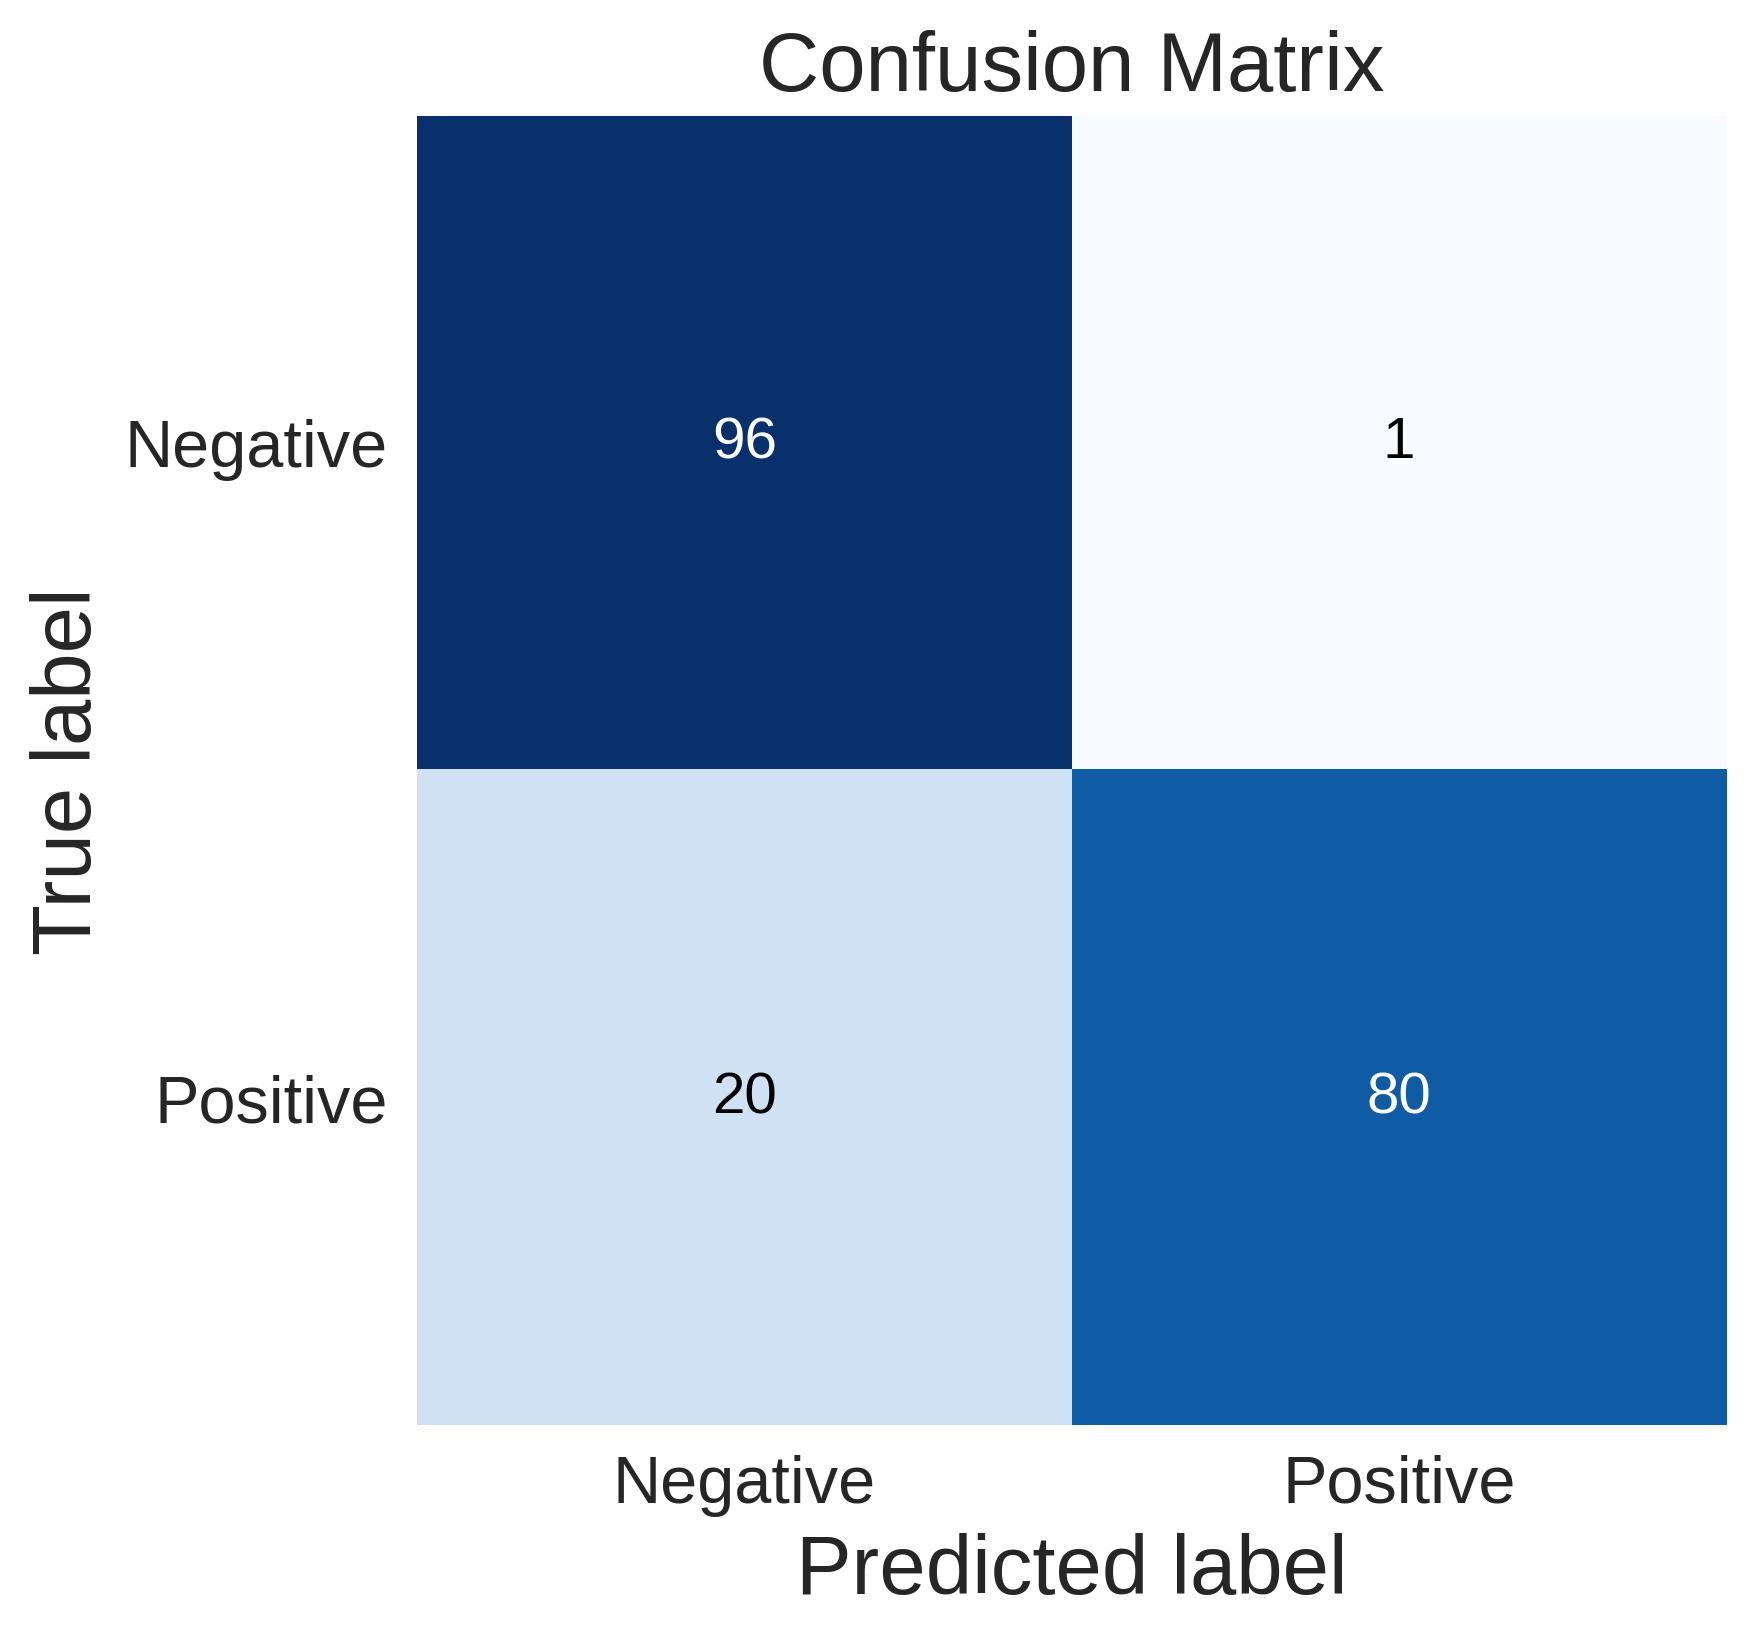

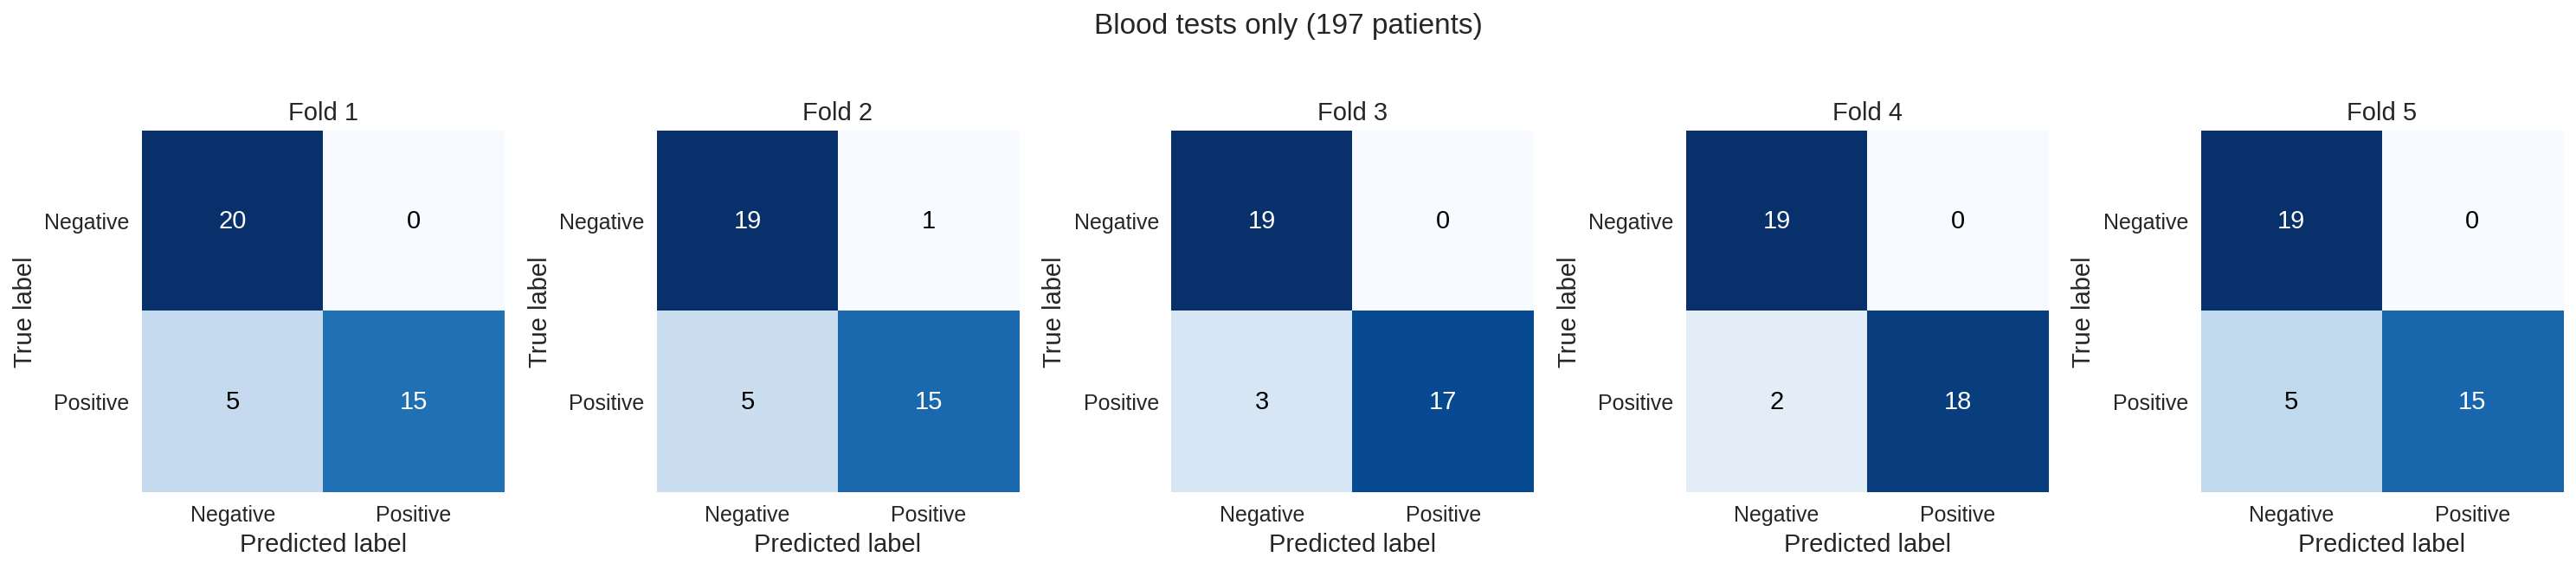

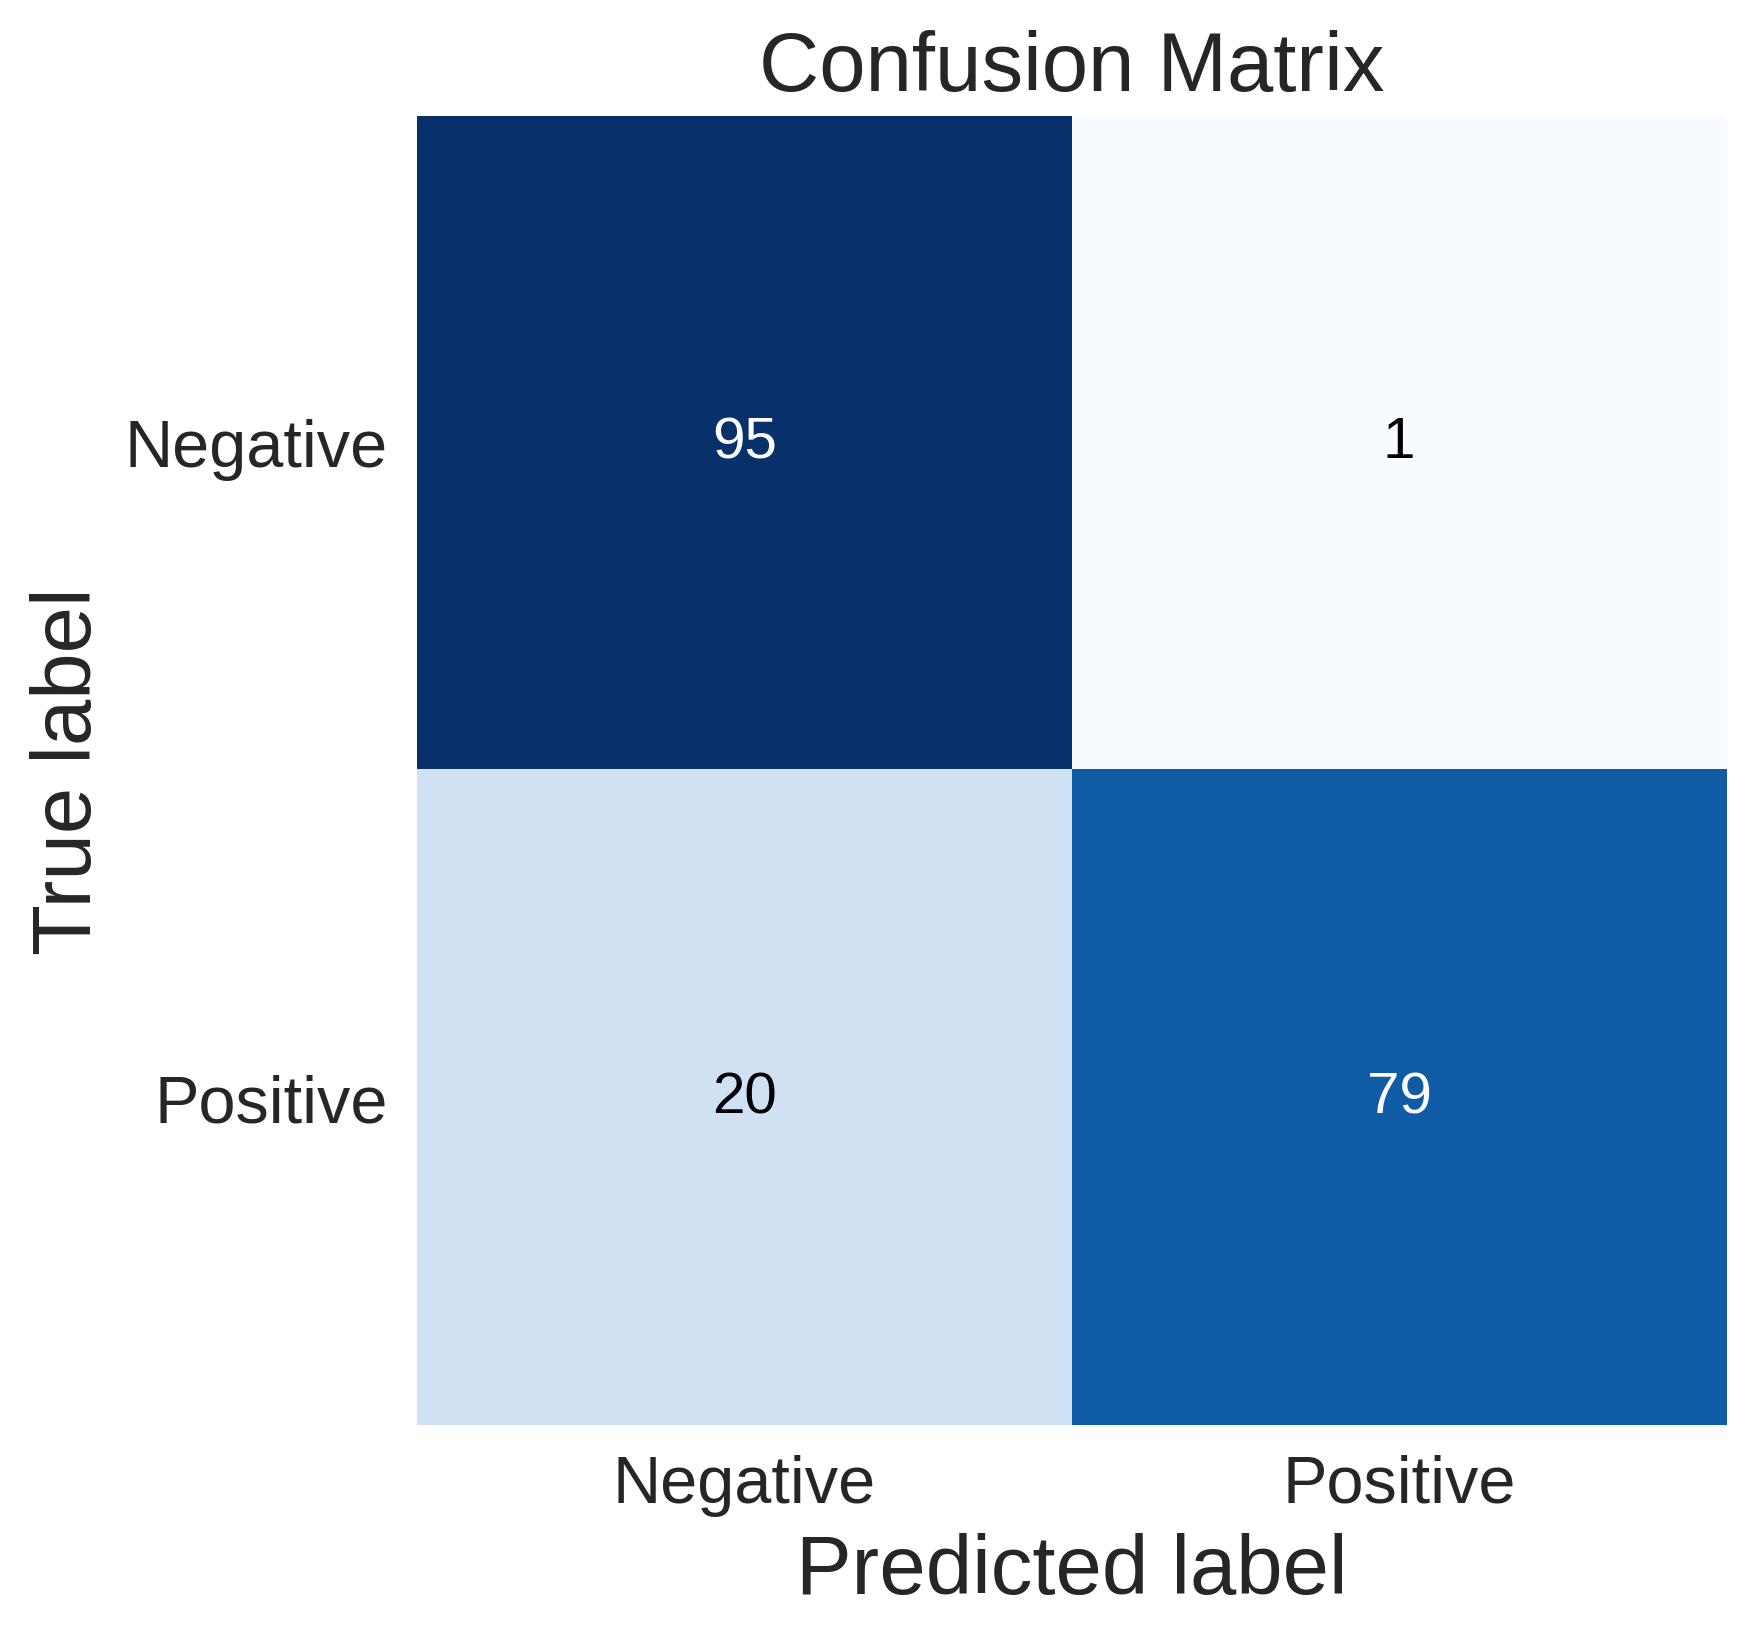

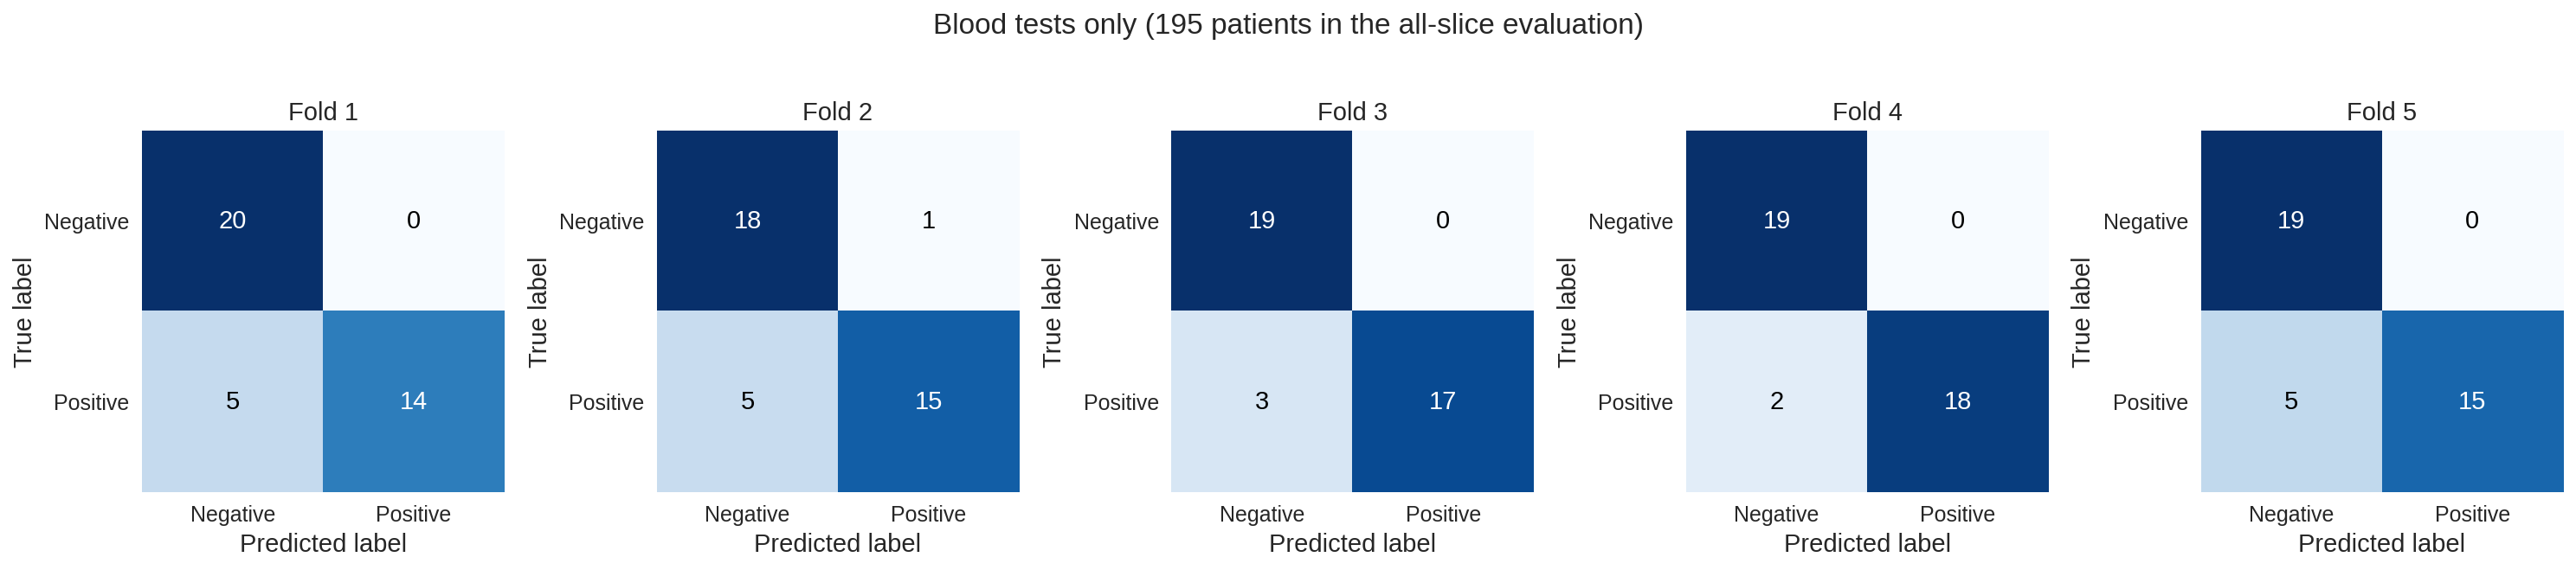

In [6]:
# ===== Confusion matrices: pooled over all folds (for the main figure) + per fold (for the supplementary material) =====
def plot_cm(ax, cm, title, label_size=16, axis_size=20, text_size=14):
    # Same style as the original cell 30
    ax.imshow(cm, cmap=plt.cm.Blues)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=text_size)
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(["Negative", "Positive"], fontsize=label_size)
    ax.set_yticklabels(["Negative", "Positive"], fontsize=label_size)
    ax.set_xlabel("Predicted label", fontsize=axis_size)
    ax.set_ylabel("True label", fontsize=axis_size)
    ax.set_title(title, fontsize=axis_size)
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)

def cm_array(r):
    return np.array([[r["TN"], r["FP"]], [r["FN"], r["TP"]]])

for df_cm, prefix, title in [
    (cm_all, "blood_only_197", "Blood tests only (197 patients)"),
    (cm_sub, "blood_only_195", "Blood tests only (195 patients in the all-slice evaluation)"),
]:
    # Pooled over all folds
    fig, ax = plt.subplots(figsize=(6, 6), dpi=300)
    plot_cm(ax, cm_array(df_cm[df_cm["fold"] == "pooled"].iloc[0]), "Confusion Matrix")
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/{prefix}_confusion_matrix_pooled.png", dpi=300, bbox_inches="tight")
    plt.show()

    # Per fold
    per_fold = df_cm[df_cm["fold"] != "pooled"]
    fig, axes = plt.subplots(1, len(per_fold), figsize=(4 * len(per_fold), 4.5), dpi=150)
    for ax, (_, r) in zip(axes, per_fold.iterrows()):
        plot_cm(ax, cm_array(r), f"Fold {r['fold']}", label_size=12, axis_size=14)
    fig.suptitle(title, fontsize=16)
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/{prefix}_confusion_matrix_per_fold.png", dpi=300, bbox_inches="tight")
    plt.show()

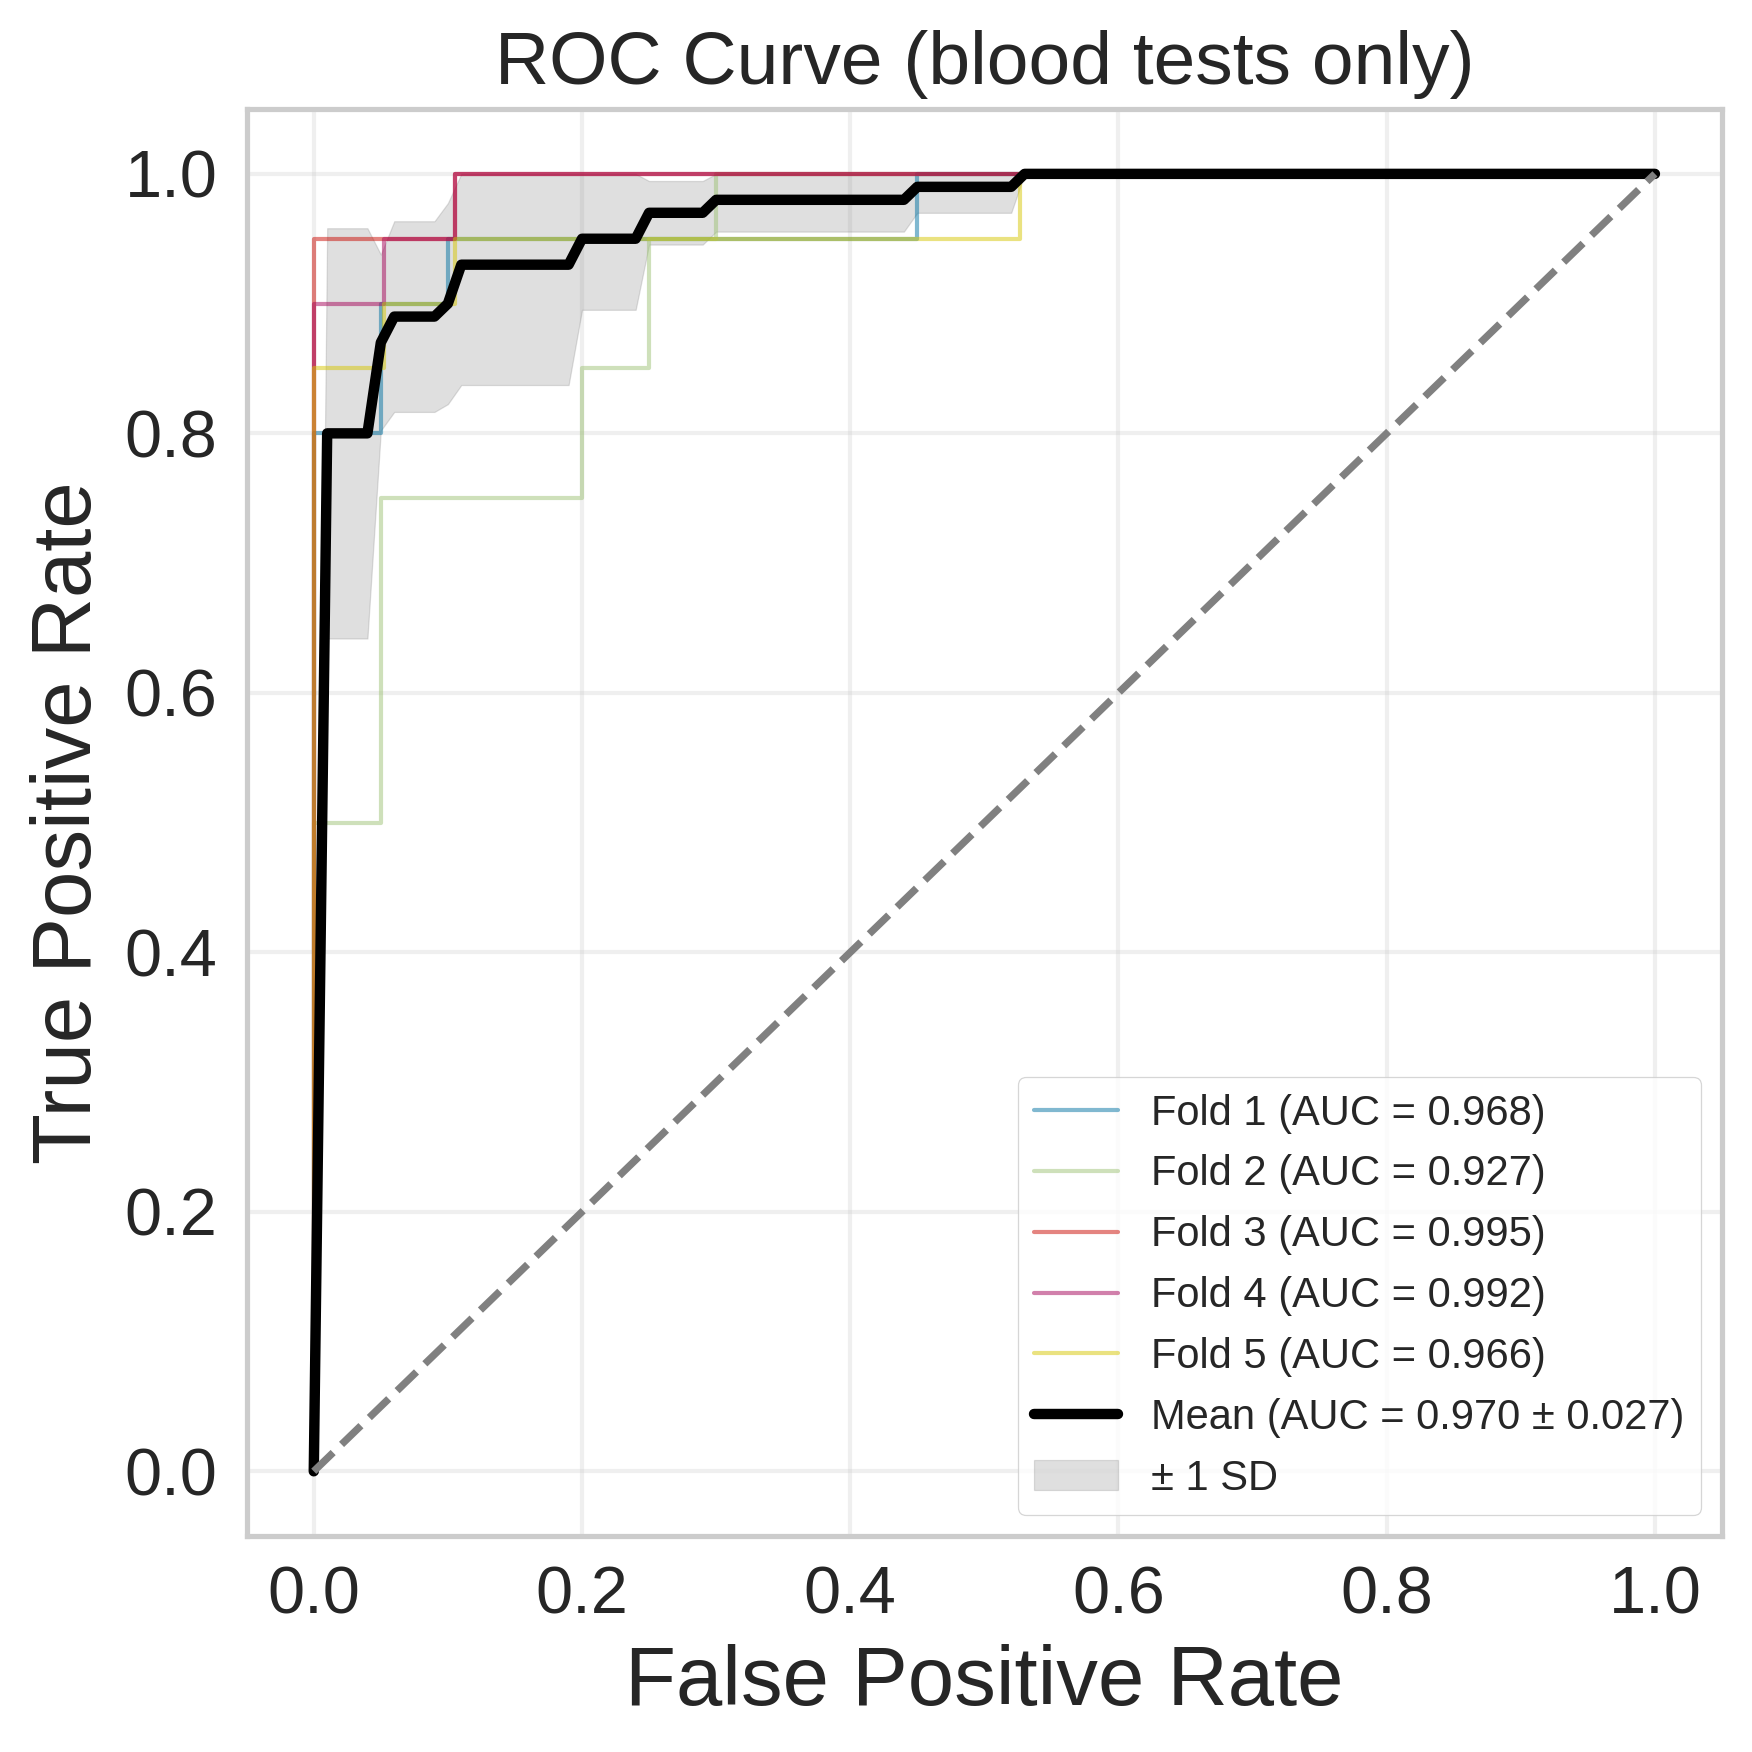

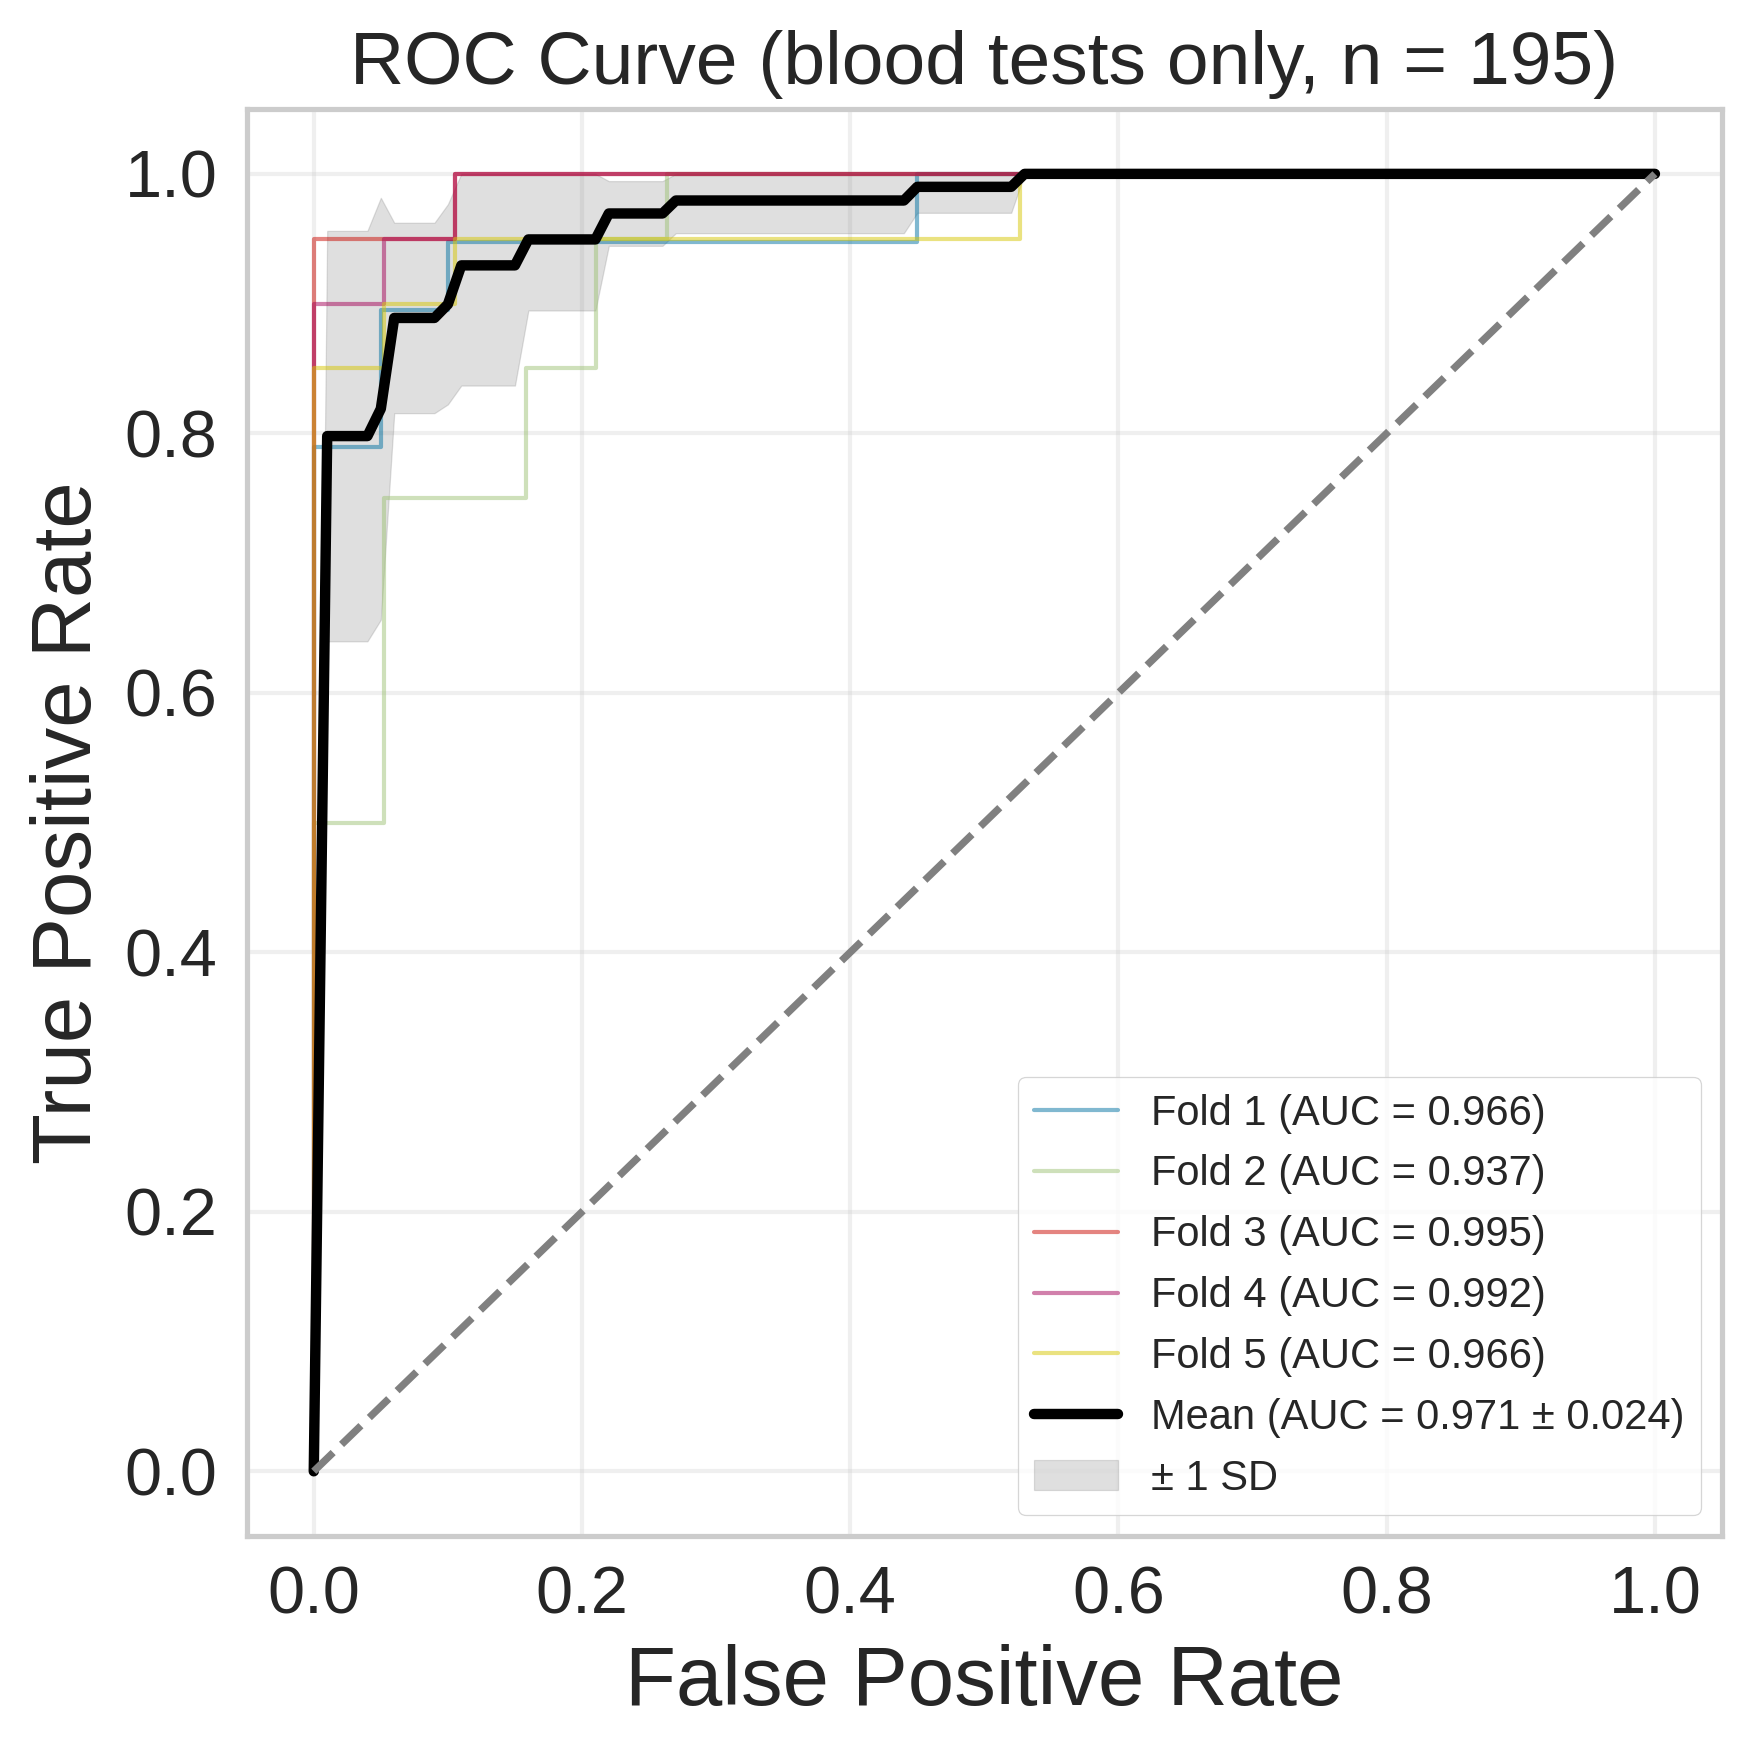

In [7]:
# ===== ROC curves: per fold (thin lines) + mean ROC ± 1 SD (thick line and band) =====
mean_fpr = np.linspace(0, 1, 101)

def plot_cv_roc(df, score_col, title, save_path):
    fig, ax = plt.subplots(figsize=(6, 6), dpi=300)
    tprs, aucs = [], []
    for k in sorted(df["fold"].unique()):
        d = df[df["fold"] == k]
        fpr, tpr, _ = roc_curve(d["label_x"], d[score_col])
        auc_k = roc_auc_score(d["label_x"], d[score_col])
        ax.plot(fpr, tpr, linewidth=1, alpha=0.5, label=f"Fold {k} (AUC = {auc_k:.3f})")
        interp = np.interp(mean_fpr, fpr, tpr)
        interp[0] = 0.0
        tprs.append(interp)
        aucs.append(auc_k)

    mean_tpr = np.mean(tprs, axis=0)
    mean_tpr[-1] = 1.0
    sd_tpr = np.std(tprs, axis=0)
    ax.plot(mean_fpr, mean_tpr, color="black", linewidth=2.5,
            label=f"Mean (AUC = {np.mean(aucs):.3f} ± {np.std(aucs, ddof=1):.3f})")
    ax.fill_between(mean_fpr, np.clip(mean_tpr - sd_tpr, 0, 1), np.clip(mean_tpr + sd_tpr, 0, 1),
                    color="gray", alpha=0.25, label="± 1 SD")
    ax.plot([0, 1], [0, 1], linestyle="--", color="gray")
    ax.set_xlabel("False Positive Rate", fontsize=20)
    ax.set_ylabel("True Positive Rate", fontsize=20)
    ax.set_title(title, fontsize=18)
    ax.tick_params(axis="both", labelsize=16)
    ax.legend(fontsize=10, loc="lower right", frameon=True)
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

plot_cv_roc(df_pred, "prob", "ROC Curve (blood tests only)", f"{OUT_DIR}/blood_only_197_roc_cv.png")
plot_cv_roc(df_pred[df_pred["in_all_slice_eval"]], "prob", "ROC Curve (blood tests only, n = 195)",
            f"{OUT_DIR}/blood_only_195_roc_cv.png")

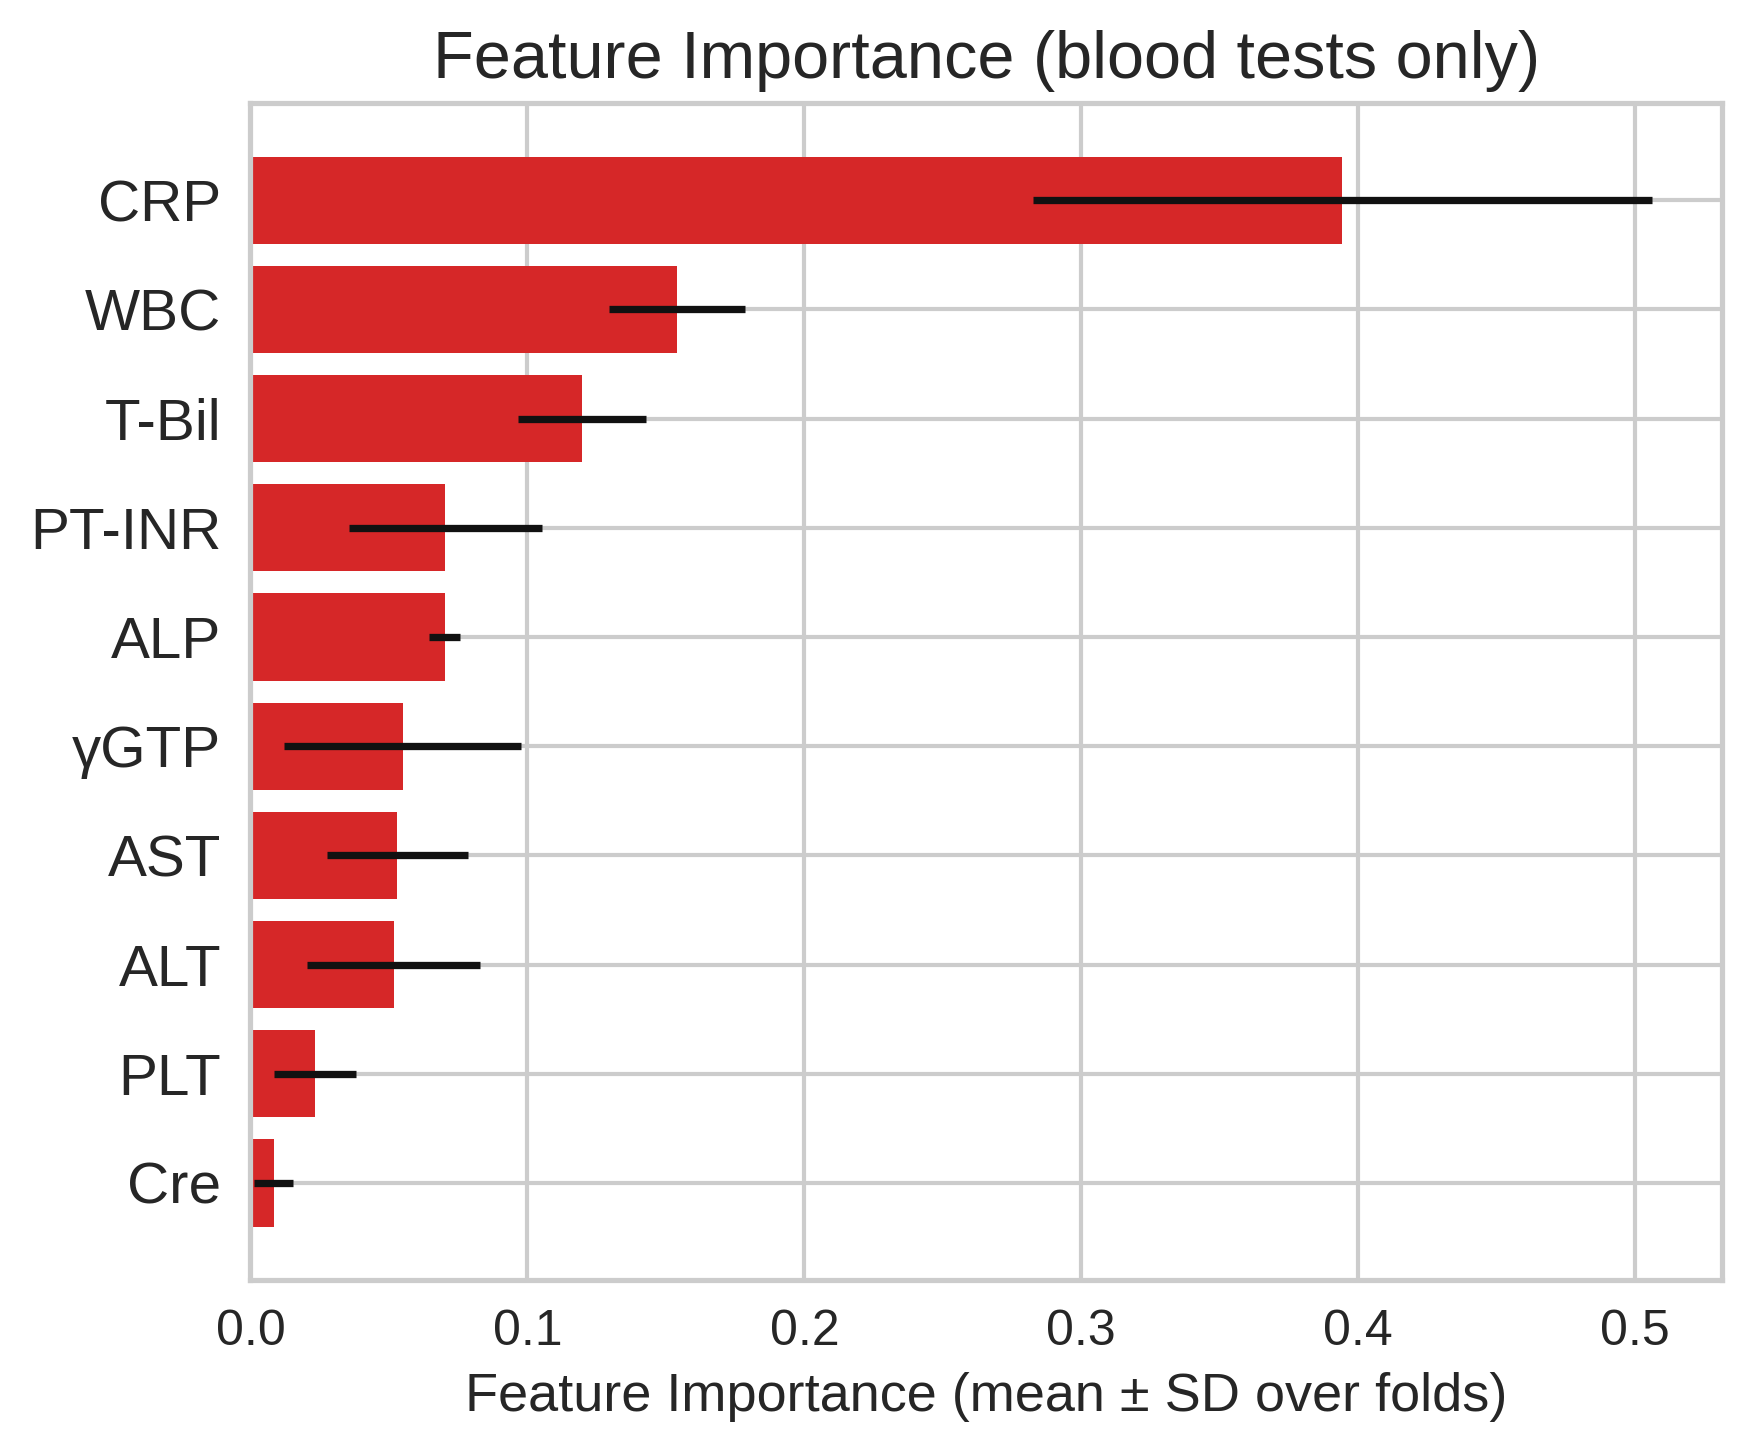

          mean    std
feature              
CRP      0.394  0.112
WBC      0.154  0.025
T-Bil    0.120  0.023
PT-INR   0.070  0.035
ALP      0.070  0.006
γGTP     0.055  0.043
AST      0.053  0.026
ALT      0.052  0.031
PLT      0.023  0.015
Cre      0.008  0.007

In [8]:
# ===== Feature importance (mean ± SD across folds) =====
imp_summary = (
    df_importance.groupby("feature")["importance"]
    .agg(["mean", "std"])
    .sort_values("mean", ascending=False)
)
imp_summary.to_csv(f"{OUT_DIR}/feature_importance_summary.csv")

fi = imp_summary.iloc[::-1]
plt.figure(figsize=(6, 5), dpi=300)
plt.barh(fi.index, fi["mean"], xerr=fi["std"], color="tab:red", capsize=3)
plt.xlabel("Feature Importance (mean ± SD over folds)", fontsize=13)
plt.title("Feature Importance (blood tests only)", fontsize=16)
plt.xticks(fontsize=12)
plt.yticks(fontsize=14)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/feature_importance_cv.png", dpi=300, bbox_inches="tight")
plt.show()

imp_summary.round(3)